**Explanation to code**

https://drive.google.com/file/d/1a24TjaEMvzWsjG949Dbd1wPmxfkupBzc/view?usp=sharing

In [ ]:
#First we install all the essential libararies needed to solve the assignment

In [18]:
import numpy as np

In [19]:
import matplotlib.pyplot as plt


**Question 1**

In [20]:
# We define a function which will generate an input data matrix X of size NxD for regression

def generate_X(N,S):

  M,D = S.shape
  Z = np.random.randn(N,M)
  X = Z @ S

  return X

N = 125
M = 5
D = 4

S = np.eye(M,D)

X = generate_X(N,S)
print(X)

#[1] https://chatgpt.com/share/670a93da-4db8-8009-90ac-843e304b5db1

[[ 9.96524634e-01 -7.29664624e-01 -1.02258535e+00 -3.02961377e-01]
 [-2.64171010e-01 -6.09178328e-02  2.21477698e-01 -1.36826894e+00]
 [-2.72227774e+00  9.42545228e-01  1.52270206e-02  1.04785113e+00]
 [ 2.44073395e-02  2.14826506e-01 -5.61782495e-01 -1.55342780e+00]
 [ 1.39928334e+00 -3.81932272e-01  5.10227645e-01 -4.84790676e-01]
 [ 1.82726150e+00 -1.65536888e+00 -2.85503697e-01  8.43238272e-02]
 [ 8.96588654e-01 -1.67224977e+00 -2.75024103e-03  2.10601984e-02]
 [ 6.19809108e-01 -1.40910693e+00 -4.08635913e-01  4.78818748e-01]
 [ 1.49419474e-01 -2.88392200e-01 -1.19941274e-01  7.40407122e-01]
 [-1.04184755e+00 -1.23349758e+00 -1.48963742e+00  1.45558082e+00]
 [-1.06487883e-01 -4.53792485e-01 -5.73930008e-01  1.09323711e+00]
 [-6.05392924e-01  1.13841552e+00  2.80129154e-02 -2.12428930e-01]
 [-1.01657207e-02  2.96364439e-01  2.48273933e-01 -1.62559937e+00]
 [-5.62692024e-01 -1.42115314e+00 -5.17137080e-01 -5.25388870e-01]
 [-1.06378962e+00 -7.89847439e-01  2.35388261e-01 -1.32579377e

**Question 2**

In [21]:
def target_vector(X ,w , sigma):

  N, D = X.shape

  if w.shape[0] != D+1:
    raise ValueError()

  weight_vector = w[:-1]
  b = w[-1]

  t = X @ weight_vector + b
  noise = np.random.normal(loc = 0 , scale = sigma , size = N)
  t_plus_noise = t + noise

  return t_plus_noise

N = 125
D = 4
X = np.random.randn(N, D)
w = np.random.randn(D + 1)
sigma = 0.5

t = target_vector(X, w, sigma)
print(t)

#[2]https://chatgpt.com/share/670a9441-b90c-8009-bd7b-b3670ce0f9e3

[ 1.28810712 -0.63831671  5.04535183 -2.69936601  2.42774    -1.2740722
 -0.26181356  1.5574885  -0.27781312 -2.97365174  1.11742523 -2.33127421
  1.88471255 -0.74072105 -0.0668338  -1.25738575 -0.37430972  0.10888263
  2.03182778  0.741457    2.90906711 -2.25829346 -1.79453299 -2.77810029
  1.19088528 -1.17825367  2.89291833  2.53071364 -3.12530737 -2.68111409
  0.61427653 -0.47567481  3.35851665  0.17242831  1.13362057 -0.31168908
 -0.17044109  1.83515968 -0.01041652 -0.02918253 -0.98716728  0.98452034
 -2.59210268 -2.92402638  1.40232512  0.78887759 -0.3072026   1.23158983
 -1.09192543  3.16011112 -0.60112689 -0.80001779 -0.11506751  0.7591615
  1.85671752 -1.24154302  0.89240577  0.28245559 -0.7544085  -0.08364699
  2.19832784 -1.2135182   1.2060812  -2.28878544 -2.14625557 -0.12545185
  0.93523904 -0.25929589 -0.78011173  0.64180413  0.65742593 -4.89411707
 -3.67394953 -1.79848005 -3.37484104  0.8335967  -0.85863646  1.47321915
  1.16532832  0.69699178  3.57452802 -0.90668645  4.6

In [23]:
import time


**Question 3**

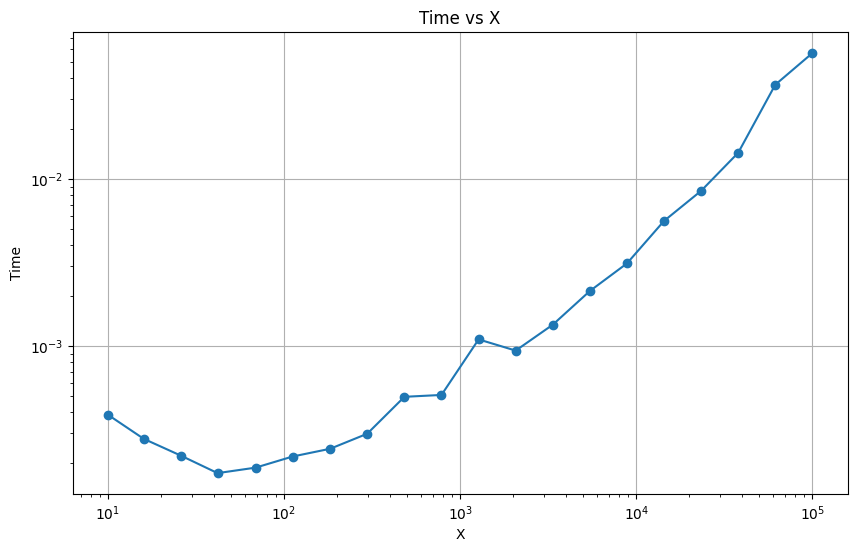

In [24]:

D = 10
N_log_values = np.logspace(1, 5, num = 20 , dtype = int)

time_taken = []

for N in N_log_values:
  X = np.random.randn(N, D)
  start_time = time.time()
  np.linalg.pinv(X)
  end_time = time.time()

  time_taken.append(end_time - start_time)

plt.figure(figsize = (10,6))
plt.loglog(N_log_values,time_taken, marker = 'o')
plt.xlabel('X')
plt.ylabel('Time')
plt.title('Time vs X')
plt.grid(True)
plt.show()

# Strange behaviour observed - After a certain value of N , time taken to compute pseudo inverse rises significantly

# This could be due to degradation of numerical stability

#[3] https://www.youngwonks.com/blog/Python-Time-Module#:~:text=As%20the%20name%20suggests%2C%20Python,time%20such%20as%20sleep%20function.
#[4] https://chatgpt.com/share/670a9441-b90c-8009-bd7b-b3670ce0f9e3

**Question 4**

In [25]:
def nrmse(t,y):

  t = np.array(t)
  y = np.array(y)
  rmse = np.sqrt(np.mean((t-y)**2))
  t_range = np.ptp(t)
  return rmse/t_range

t = [1,2,3,4,5]
y = [2,3,4,5,6]

nrmse_value = nrmse(t,y)
print(nrmse_value)

# No refernces used - I first calculatedthe square root of sum of squared mean differences and then divided them by difference of extreme ends of array t

0.25


**Question 5**

In [26]:
def gradient_of_mean_squared_error(X, w, y):

  y_predicted = X @ w
  error = y_predicted - y
  return (-2/len(y)) * (X.T @ error)

X = np.random.randn(125,5)
w = np.random.randn(5)
y = np.random.randn(125)

grad = gradient_of_mean_squared_error(X, w, y)
print(grad)

# No references used - Formula for mean square error is used

[-1.85154749 -1.93282176  0.01130685 -0.63190834 -1.42717733]


**Question 6**

In [27]:
def L2_norm_of_weights(w):

  gradient = 2*w
  return gradient

w = np.array([5.0, 8.0, 10.0])

grad = L2_norm_of_weights(w)
print(f"Gradient of squared L2 norm: {grad}")

# [6] https://chatgpt.com/share/670a95d1-a53c-8009-b5d3-43038b9531e0

Gradient of squared L2 norm: [10. 16. 20.]


**Question 7**

In [28]:
def L1_norm_of_weights(w):

  gradient = np.sign(w)
  return gradient

w = np.array([5.0, -8.0, 10.0])

grad = L1_norm_of_weights(w)
print(f"Gradient of L1 norm: {grad}")

# [7] https://g.co/gemini/share/201ceaa9f7bd

Gradient of L1 norm: [ 1. -1.  1.]


**Question 8**

In [29]:
def gradient_desecent_for_linear_regularisation(X, y, w, learning_rate = 0.05, lambda1 = 0.2, lambda2 = 0.3, max_iterations = 1000, tolerance= 1e-5):

  number_of_samples = len(y)
  loss = []

  for i in range(max_iterations):
    y_predicted = X @ w
    error = y_predicted - y


    gradient_mse = (-2/number_of_samples) * (X.T @ error)
    gradient_l1 = lambda1 * np.sign(w)
    gradient_l2 = 2 * lambda2 * w

    gradient = gradient_mse + gradient_l1 + gradient_l2

    w = w - learning_rate * gradient

    mse_loss = np.mean(error**2)
    l1_loss = lambda1 * np.sum(np.abs(w))
    l2_loss = lambda2 * np.sum(w**2)
    total_loss = mse_loss + l1_loss + l2_loss
    loss.append(total_loss)

    if i > 0 and np.abs(loss[i] - loss[i-1]) < tolerance:
      break

  return w, loss

X = np.array([[1, 2], [2, 3], [3, 4], [4, 5]])  # Input data (4 samples, 2 features)
y = np.array([6, 8, 10, 12])                    # True target values
w = np.random.randn(2)                          # Initial weights

w_optimal, loss = gradient_desecent_for_linear_regularisation(X, y, w)
print(w_optimal)
print(loss)

# [8] https://g.co/gemini/share/6e5f2fce6af3

[nan nan]
[122.42888749682534, 1198.364630084436, 11411.98286163069, 107659.44587589162, 1012358.1965682851, 9509297.982238868, 89291309.58977318, 838339128.0765197, 7870709623.540418, 73892896959.86739, 693728841139.814, 6512927402430.212, 61145223703862.97, 574048753833515.8, 5389332752138330.0, 5.059658589422418e+16, 4.75015110302049e+17, 4.459576682290962e+18, 4.1867771663712166e+19, 3.930665237239786e+20, 3.69022008873343e+21, 3.4644833587022654e+22, 3.252555309451484e+23, 3.0535912416630897e+24, 2.8667981276322038e+25, 2.691431450437924e+26, 2.5267922364623677e+27, 2.3722242694338373e+28, 2.227111474891012e+29, 2.090875464643561e+30, 1.962973231442025e+31, 1.8428949846684557e+32, 1.7301621184213555e+33, 1.6243253038961451e+34, 1.5249626984578063e+35, 1.431678264267439e+36, 1.3441001897611596e+37, 1.2618794076896804e+38, 1.1846882038118078e+39, 1.11221891069641e+40, 1.0441826814266282e+41, 9.803083383185836e+41, 9.203412920658272e+42, 8.640425270014648e+43, 8.111876484334453e+44, 

<ipython-input-29-cfdbfdb7f381>:19: RuntimeWarning: overflow encountered in square
  mse_loss = np.mean(error**2)
/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:118: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
<ipython-input-29-cfdbfdb7f381>:21: RuntimeWarning: overflow encountered in square
  l2_loss = lambda2 * np.sum(w**2)
<ipython-input-29-cfdbfdb7f381>:25: RuntimeWarning: invalid value encountered in scalar subtract
  if i > 0 and np.abs(loss[i] - loss[i-1]) < tolerance:
<ipython-input-29-cfdbfdb7f381>:11: RuntimeWarning: overflow encountered in matmul
  gradient_mse = (-2/number_of_samples) * (X.T @ error)
<ipython-input-29-cfdbfdb7f381>:15: RuntimeWarning: invalid value encountered in add
  gradient = gradient_mse + gradient_l1 + gradient_l2


**Question 9**

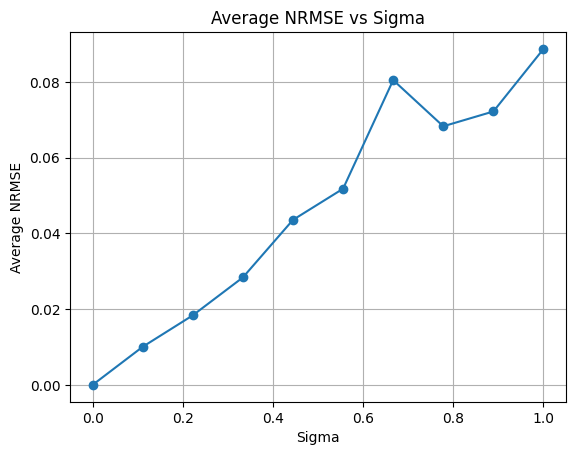

'comment on the results - Increasing σ amplifies noise in the target variable, making it \nharder for the model to discern the underlying pattern and thus increasing the average NRMSE.'

In [30]:
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

n= 100
d = 10
sigma_values = np.linspace(0,1,10)
num_runs = 5

def generate_data(n, d, sigma):
  X = np.random.randn(n, d)
  w_true = np.random.randn(d)
  noise = np.random.randn(n) * sigma
  y = X @ w_true + noise
  return X, y

def compute_nrmse(t_true, t_pred):
  rmse = np.sqrt(np.mean((t_true - t_pred)**2))
  t_range = np.ptp(t_true)
  return rmse / t_range

average_nrmse = []

for sigma in sigma_values:
  nrmse_values = []
  for run in range(num_runs):
    X, y = generate_data(n, d, sigma)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

    X_train = sm.add_constant(X_train)
    model = sm.OLS(y_train, X_train)
    results = model.fit()

    X_test = sm.add_constant(X_test)
    y_pred = results.predict(X_test)

    nrmse = compute_nrmse(y_test, y_pred)
    nrmse_values.append(nrmse)

  average_nrmse.append(np.mean(nrmse_values))

plt.plot(sigma_values, average_nrmse, marker = 'o')
plt.xlabel('Sigma')
plt.ylabel('Average NRMSE')
plt.title('Average NRMSE vs Sigma')
plt.grid(True)
plt.show()

"""comment on the results - Increasing σ amplifies noise in the target variable, making it
harder for the model to discern the underlying pattern and thus increasing the average NRMSE."""

# [9] https://g.co/gemini/share/a17d92e13583

**Question 10**

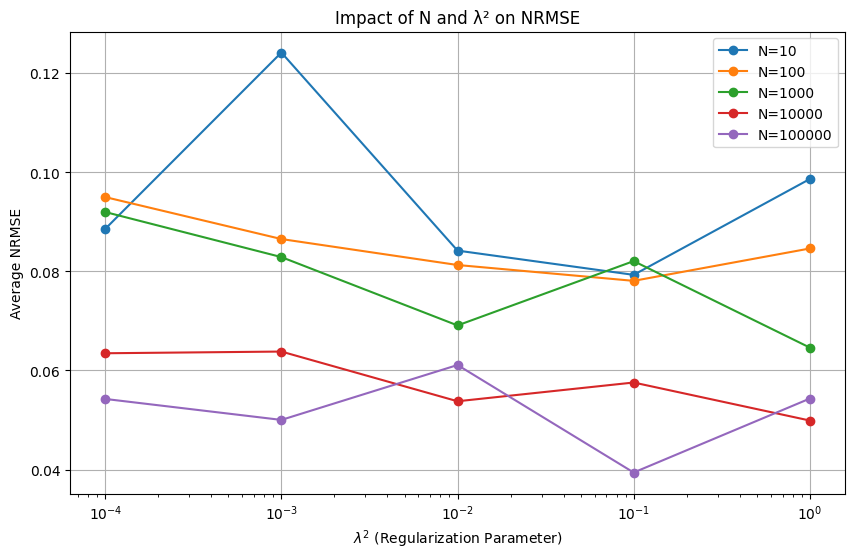

'\nThe regularization parameter 𝜆2 affects the complexity of the model. A small 𝜆2\nallows for a more complex model, potentially reducing bias but increasing variance. Conversely, a large 𝜆2\ncan regularize the model too much, leading to underfitting.\n'

In [31]:
 def generate_data_and_calculate_nrmse(N, G, sigma, lambda_squared):
    # Generate data
    X = np.random.randn(N, G.shape[1])
    true_weights = np.random.randn(G.shape[1])
    y = X @ true_weights + np.random.normal(0, sigma, N)

    # Apply linear regression with gradient descent (pseudo-code)
    # Initialize weights
    weights = np.zeros(G.shape[1])
    # Learning rate
    alpha = 0.01
    # Number of iterations
    num_iterations = 1000

    for _ in range(num_iterations):
        predictions = X @ weights
        # Compute gradient with L2 regularization
        gradient = (X.T @ (predictions - y) + lambda_squared * weights) / N
        weights -= alpha * gradient

    # Calculate predictions and NRMSE
    predictions = X @ weights
    nrmse = np.sqrt(np.mean((y - predictions) ** 2)) / (np.max(y) - np.min(y))

    return nrmse

# Parameters
N_values = [10, 100, 1000, 10000, 100000]
lambda_squared_values = [0.0001, 0.001, 0.01, 0.1, 1]
sigma = 1.0  # Noise variance
G = np.random.randn(5, 5)  # Example generator matrix

# Store results
results = np.zeros((len(N_values), len(lambda_squared_values)))

# Run experiments
for i, N in enumerate(N_values):
    for j, lambda_squared in enumerate(lambda_squared_values):
        nrmse_values = []
        for _ in range(5):  # Run 5 times
            nrmse = generate_data_and_calculate_nrmse(N, G, sigma, lambda_squared)
            nrmse_values.append(nrmse)
        results[i, j] = np.mean(nrmse_values)

# Plotting the results
plt.figure(figsize=(10, 6))
for i, N in enumerate(N_values):
    plt.plot(lambda_squared_values, results[i, :], marker='o', label=f'N={N}')
plt.xscale('log')
plt.xlabel(r'$\lambda^2$ (Regularization Parameter)')
plt.ylabel('Average NRMSE')
plt.title('Impact of N and λ² on NRMSE')
plt.legend()
plt.grid()
plt.show()

"""
The regularization parameter 𝜆2 affects the complexity of the model. A small 𝜆2
allows for a more complex model, potentially reducing bias but increasing variance. Conversely, a large 𝜆2
can regularize the model too much, leading to underfitting.
"""

# [10] https://chatgpt.com/share/670a97d1-907c-8009-a585-e6aba2297893
# [11] https://g.co/gemini/share/10d41ab40892


**Question 11**

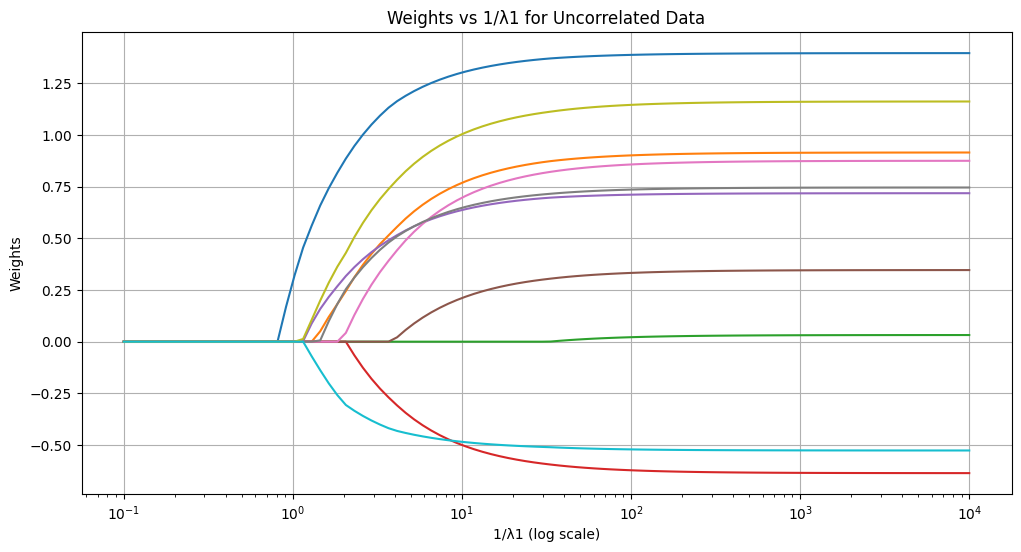

<ipython-input-32-1b48b02f36a7>:32: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X_correlated = np.random.multivariate_normal(np.zeros(n_features), correlation_matrix, n_samples)


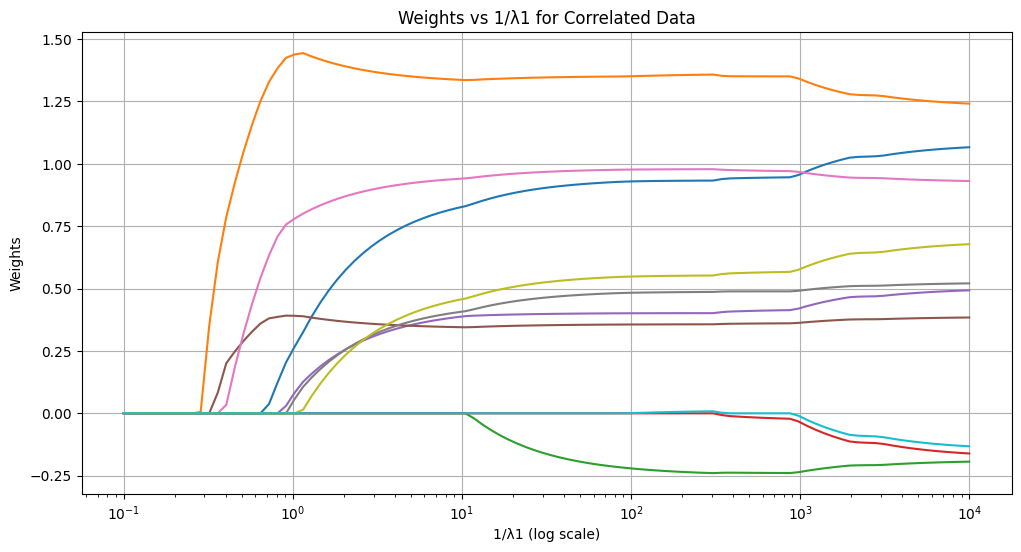

"\nAs 𝜆1 increases , weights for some features may shrink to zero, effectively eliminating those\nvariables. this demonstarates Lasso's ability to perform variable selection.\n"

In [32]:
from sklearn.linear_model import Lasso

np.random.seed(42)
n_samples = 100
n_features = 10

X = np.random.randn(n_samples, n_features)
true_weights = np.random.randn(n_features)
y = X @ true_weights + np.random.randn(n_samples) * 0.5

lambda1_values = np.logspace(-4, 1, 100)
weights = []
for lambda1 in lambda1_values:
    model = Lasso(alpha=lambda1)
    model.fit(X, y)
    weights.append(model.coef_)
weights = np.array(weights)

plt.figure(figsize=(12, 6))
for i in range(n_features):
    plt.plot(1/lambda1_values, weights[:, i])
plt.xscale('log')
plt.xlabel('1/λ1 (log scale)')
plt.ylabel('Weights')
plt.title('Weights vs 1/λ1 for Uncorrelated Data')
plt.grid()
plt.show()

correlation_matrix = np.random.rand(n_features, n_features)
correlation_matrix = (correlation_matrix + correlation_matrix.T) / 2
correlation_matrix[np.diag_indices(n_features)] = 1
X_correlated = np.random.multivariate_normal(np.zeros(n_features), correlation_matrix, n_samples)
y_correlated = X_correlated @ true_weights + np.random.randn(n_samples) * 0.5

weights_correlated = []
for lambda1 in lambda1_values:
    model = Lasso(alpha=lambda1)
    model.fit(X_correlated, y_correlated)
    weights_correlated.append(model.coef_)
weights_correlated = np.array(weights_correlated)

plt.figure(figsize=(12, 6))
for i in range(n_features):
    plt.plot(1/lambda1_values, weights_correlated[:, i])
plt.xscale('log')
plt.xlabel('1/λ1 (log scale)')
plt.ylabel('Weights')
plt.title('Weights vs 1/λ1 for Correlated Data')
plt.grid()
plt.show()

"""
As 𝜆1 increases , weights for some features may shrink to zero, effectively eliminating those
variables. this demonstarates Lasso's ability to perform variable selection.
"""

# [12] https://chatgpt.com/share/670aa9a8-d8e0-8009-b84d-c12689648cb4

**Question 12**

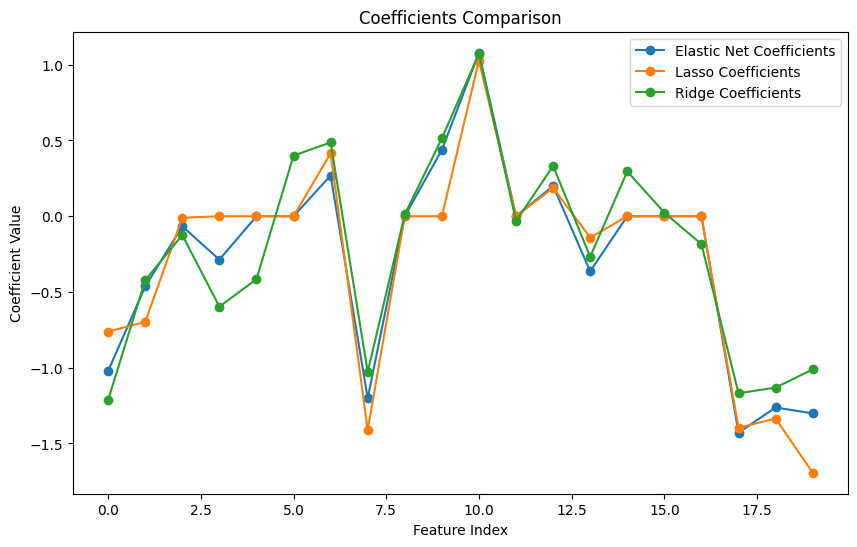

In [37]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import train_test_split

def input_data_matrix(num_samples, G):
    return np.dot(np.random.randn(num_samples, G.shape[0]), G)

def target_vector(X, w, noise):
    return X @ w.flatten() + np.random.normal(0, noise, X.shape[0])

G = np.random.randn(10, 20)
X = input_data_matrix(100, G)
w = np.random.randn(20, 1)
t = target_vector(X, w, 0.1)

X_train, X_test, t_train, t_test = train_test_split(X, t, test_size=0.2, random_state=42)


models = {
    "Elastic Net": ElasticNet(alpha=0.1, l1_ratio=0.5),
    "Lasso": Lasso(alpha=0.1),
    "Ridge": Ridge(alpha=0.1),
}

for name, model in models.items():
    model.fit(X_train, t_train)

plt.figure(figsize=(10, 6))
for name, model in models.items():
    plt.plot(model.coef_, label=f"{name} Coefficients", marker='o')

plt.title("Coefficients Comparison")
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.legend()
plt.show()

# [13] https://chatgpt.com/share/670a9a9e-d514-8009-8667-43ec48378fe3

**Question 14**

In [38]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

def gradient_calculation(X, y, w, bias):

  z = np.dot(X, w) + bias
  y_pred = sigmoid(z)
  gradient_w = np.dot(X.T, (y_pred - y))
  gradient_bias = np.sum(y_pred - y)

  return gradient_w, gradient_bias

X = np.random.randn(125,5)
y = np.random.randint(0, 2, size = 125)
w = np.random.randn(5)
bias = 0.75

gradient_w, gradient_bias = gradient_calculation(X, y, w, bias)
print(gradient_w)
print(gradient_bias)

# No references used - I was aware of the formula for sigmoid function


[-25.8466351   -7.33516418 -11.8651161   20.64121785   0.13016249]
17.38116639914033


**Question 13**

In [39]:
def generate_linear_binary_classification_vector_t(X, w, bias, sigma):

  Z = X @ w + bias
  noise = np.random.normal(0, sigma, size = Z.shape)
  Z_plus_noise = Z + noise

  t = (Z_plus_noise > 0).astype(int)

  return t

X = np.random.randn(125,5)
w = np.random.randn(5)
sigma = 0.1
bias = 0.75

t = generate_linear_binary_classification_vector_t(X, w, bias, sigma)
print(t)

# No references used - I was aware of the noise function from the questions before

[0 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 0 0 0 1 1 1 0 1 1 1
 1 1 1 0 1 0 1 1 0 0 1 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 1 1 1 1 1 1 0 1 0 1 1
 0 0 0 0 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1
 0 1 0 0 0 1 1 1 1 1 1 1 0 0]
